## SPAM alignment pipeline
Pipeline designed to use the SPAM sofware (https://www.spam-project.dev/) to register 3D images of fly legs.

This is a challenging registration problem because each leg is more or less rigid but they can move relative to each other. The SPAM Discrete Image correlation package is made precisely to register rigid particles. It was developed (and recommended) by Edward Ando from the EPFL Imaging Processing hub.

This script will:
- Load a 3D image projection of fly legs, collected using SCAPE and already preprocessed and saved in an h5 file. Also load the voxel sizes, saved in the same h5 file.

- REMOVE THE ANISOTROPY - this is very important, as otherwise rotating a leg (or mirroring across a tilted plane) will make it look very different depending on the original angle in relation to the axes. Reduce resolution in some directions and increase it in the others to keep file size approximately similar. This is done on the whole volumes, before finding the symmetry plane.

- Split the two hemibodies to process one at a time, by first finding the (slightly tilted) symmetry plane, rotating the volume so the plane is perpendicular to axis 2, and cropping. Flip one side to have two equivalent hemi

- Load the REFERENCE 3D projection, which has been manually segmented to isolate all the leg segments (femur, tibia, etc.). Split this reference too into two hemi

- Normalize the new image to match the reference image range

- Crop/pad the images to have identical dimensions for both.

- Replace the 'blank' background (either from the padding or from the scape deskewing) with random values matching the rest of the background.

- Perform a coarse, rigid alignment to get the two images approximately aligned - by then transfering the manual segmentation to the new image, this gives SPAM a decent starting point to find the matching segment in the new image. It is ESSENTIAL that there is some overlap between the new data and the manual segmentation, otherwise SPAM will not converge - this is why we do the pre-alignment.

- Run spam to align each segment one by one, using seed expansion = 0 (the manual segmentation already has some margins by design)

In [21]:
from pathlib import Path
import tifffile
import h5py

import numpy as np
import matplotlib.pyplot as plt

### Load images, voxel sizes, and manual segmentation

In [22]:
# set paths to target and reference image folders
main_path = Path('/mnt/labserver/data/MA/SCAPE/')
#folder_ref = main_path / '20260716_MA12_pupa-P15/sample2_combined'
folder_ref = main_path / '20261016_V7xPR_pupa_long_paired' / 'sample1_run3_short'

#folder_tar = main_path / '20260716_MA12_pupa-P15/sample4_combined'
folder_tar = main_path / '20261016_V7xPR_pupa_long_paired' / 'sample1_run1_short'

In [23]:
# load the reference and target images and voxel ratio
PROJECTION_FILE_NAME = "projection_images.h5"
PROJ_TYPE = 'min_proj'

h5_path_ref = folder_ref / 'analysis' / PROJECTION_FILE_NAME
with h5py.File(h5_path_ref, 'r') as f:
    proj_ref = f[PROJ_TYPE][:]
    voxel_sizes_ref = f['voxel_sizes_xyz'][:]

h5_path_tar = folder_tar / 'analysis' / PROJECTION_FILE_NAME
with h5py.File(h5_path_tar, 'r') as f:
    proj_tar = f[PROJ_TYPE][:]
    voxel_sizes_tar = f['voxel_sizes_xyz'][:]

In [24]:
# load the manual segmentation
segment_masks_path = folder_ref / 'analysis' /'leg_segments.tif'
segment_masks = tifffile.imread(segment_masks_path)
segment_ids = {1:'LF_femur', 2:'RF_femur', 
               3:'LF_tibia', 4:'RF_tibia',
               5:'LM_tibia', 6:'RM_tibia',}

# check that manual segmentation dimensions match ref. If y and z are swapped
# (e.g. labels saved with a different axis order), transpose them to match
if segment_masks.shape != proj_ref.shape:
    if np.swapaxes(segment_masks, 1, 2).shape == proj_ref.shape:
        print(f'Swapping axes 1 and 2 of segment_masks {segment_masks.shape} '
              f'to match proj_ref {proj_ref.shape}')
        segment_masks = np.swapaxes(segment_masks, 1, 2)
    else:
        raise ValueError(f'segment_masks shape {segment_masks.shape} does not '
                         f'match proj_ref shape {proj_ref.shape}')

Swapping axes 1 and 2 of segment_masks (316, 850, 960) to match proj_ref (316, 960, 850)


In [68]:
# also load the muscle manual segmentation
muscle_masks_path = folder_ref / 'analysis' /'leg_muscles.tif'
muscle_masks = tifffile.imread(muscle_masks_path)
if muscle_masks.shape != proj_ref.shape:
    if np.swapaxes(muscle_masks, 1, 2).shape == proj_ref.shape:
        print(f'Swapping axes 1 and 2 of muscle_masks {muscle_masks.shape} '
              f'to match proj_ref {proj_ref.shape}')
        muscle_masks = np.swapaxes(muscle_masks, 1, 2)
    else:
        raise ValueError(f'muscle_masks shape {muscle_masks.shape} does not '
                         f'match proj_ref shape {proj_ref.shape}')

Swapping axes 1 and 2 of muscle_masks (316, 850, 960) to match proj_ref (316, 960, 850)


In [25]:
# function to get plotting aspect ratio based on projection axis
def get_aspect_ratio(voxel_sizes_xyz, proj_ax):
    # max_proj/min_proj/std_image loaded from projection_images.h5 are stored with
    # axes in (Z, X, Y) order, while voxel_sizes_xyz is (X, Y, Z) - reorder to match
    # before indexing by proj_ax (an axis index into the volume, not into voxel_sizes_xyz)
    voxel_sizes_zxy = [voxel_sizes_xyz[2], voxel_sizes_xyz[0], voxel_sizes_xyz[1]]
    row_size, col_size = [v for ax, v in enumerate(voxel_sizes_zxy) if ax != proj_ax]
    aspect_ratio = row_size / col_size

    return aspect_ratio

In [26]:
# almost always, project across first axis
PROJ_AX = 0
ASPECT_XY_REF = get_aspect_ratio(voxel_sizes_ref, PROJ_AX)
ASPECT_XY_TAR = get_aspect_ratio(voxel_sizes_tar, PROJ_AX)

### Remove the anisotropy

In [27]:
from scipy.ndimage import zoom


def resample_to_isotropic(volume: np.ndarray, voxel_sizes_xyz, target_voxel_size: float,
                           order: int = 1) -> np.ndarray:
    """
    Resamples `volume` (stored in (Z, X, Y) order - see
    `get_projection_images`) to isotropic `target_voxel_size` voxels,
    removing the anisotropy described by `voxel_sizes_xyz` (x, y, z).

    Using the same `target_voxel_size` for every volume - rather than
    each volume's own `target_isotropic_voxel_size` - is what makes the
    resampled voxel size identical across images, even when their
    original voxel sizes differ slightly (e.g. `voxel_sizes_ref` vs
    `voxel_sizes_tar`).

    Parameters
    ----------
    volume : ndarray, shape (Z, X, Y)
        Volume to resample.

    voxel_sizes_xyz : array-like of float
        `volume`'s own original voxel size (x, y, z).

    target_voxel_size : float
        Desired isotropic voxel size (same unit as `voxel_sizes_xyz`) -
        use the same value for every volume that needs to end up on a
        shared voxel grid (see `target_isotropic_voxel_size`).

    order : int
        Spline interpolation order passed to `scipy.ndimage.zoom`. Use
        `1` (linear, default) for intensity images, `0`
        (nearest-neighbor) for label/segmentation volumes, so class
        values aren't blended into new, meaningless ones.

    Returns
    -------
    ndarray
        `volume`, resampled to `target_voxel_size` isotropic voxels.
    """
    voxel_size_z, voxel_size_x, voxel_size_y = voxel_sizes_xyz[2], voxel_sizes_xyz[0], voxel_sizes_xyz[1]
    zoom_factors = (voxel_size_z / target_voxel_size,
                    voxel_size_x / target_voxel_size,
                    voxel_size_y / target_voxel_size)
    return zoom(volume, zoom_factors, order=order)

In [28]:
TARGET_VOXEL_SIZES = 1.5 # this keeps images at a manageable size for SPAM

In [69]:
# resample the whole volumes to isotropic voxels BEFORE finding the symmetry plane:
# a tilted mirror plane is only a proper (orthogonal) reflection in voxel
# coordinates if voxels are isotropic (they are ~0.9 x 8 x 1.1 um raw)
iso = {
    'ref': resample_to_isotropic(proj_ref, voxel_sizes_ref, TARGET_VOXEL_SIZES),
    'tar': resample_to_isotropic(proj_tar, voxel_sizes_tar, TARGET_VOXEL_SIZES),
    # nearest-neighbor (order=0) for labels, so segment IDs aren't blended
    'masks': resample_to_isotropic(segment_masks, voxel_sizes_ref, TARGET_VOXEL_SIZES, order=0),
    'muscles': resample_to_isotropic(muscle_masks, voxel_sizes_ref, TARGET_VOXEL_SIZES, order=0),
}
for key, vol in iso.items():
    print(f'{key}: {vol.shape}')

ref: (193, 640, 642)
tar: (193, 640, 642)
masks: (193, 640, 642)
muscles: (193, 640, 642)


### Smooth the labels

In [30]:
from scipy.ndimage import gaussian_filter, find_objects


def smooth_labels(labels: np.ndarray,
                  sigma: float) -> np.ndarray:
    """
    Smooths a label volume in all directions, e.g. to remove the slice-by-slice
    jaggedness of manually drawn masks.

    Each label is converted to a binary mask and blurred with a 3D Gaussian.
    A fixed 0.5 threshold would shrink thin or jagged structures (convex
    corners lose more than concave ones gain), so instead each label gets its
    own threshold, chosen so that the smoothed label keeps the same number of
    voxels as the raw label. This keeps the volume and the outline position,
    with the smoothed surface passing through the raw jagged one. Each voxel is
    then assigned the label whose blurred value is furthest above its own
    threshold, or background (0) if none reach it. This keeps labels
    non-overlapping and does not blend label IDs. To save time and memory,
    each label is only blurred within its bounding box padded by 4 `sigma`.

    Parameters
    ----------
    labels : np.ndarray
        Integer label volume (0 = background). Should be isotropic, so that
        `sigma` means the same physical distance along every axis.
    sigma : float
        Standard deviation of the Gaussian, in voxels.

    Returns
    -------
    np.ndarray
        Smoothed label volume, same shape and dtype as `labels`.
    """
    pad = int(np.ceil(4 * sigma))
    best_score = np.zeros(labels.shape, dtype=np.float32)  # score must be > 0 to keep a voxel
    smoothed = np.zeros_like(labels)
    for label_idx, bbox in enumerate(find_objects(labels), start=1):
        if bbox is None:  # label not present
            continue
        bbox = tuple(slice(max(s.start - pad, 0), min(s.stop + pad, n))
                     for s, n in zip(bbox, labels.shape))
        raw = labels[bbox] == label_idx
        score = gaussian_filter(raw.astype(np.float32), sigma).ravel()
        # threshold = n-th highest blurred value, where n = raw voxel count,
        # so that exactly n voxels end up above it (volume preserved)
        n_voxels = raw.sum()
        threshold = np.partition(score, score.size - n_voxels)[score.size - n_voxels]
        # shift so that the threshold is at 0 (ties at the threshold are kept)
        score = (score - threshold + 1e-6).reshape(raw.shape)
        better = score > best_score[bbox]
        best_score[bbox][better] = score[better]
        smoothed[bbox][better] = label_idx
    return smoothed


SMOOTH_SIGMA_UM = 10  # Gaussian sigma in um; increase for smoother masks

iso['masks_raw'] = iso['masks']  # keep the unsmoothed version for comparison
iso['masks'] = smooth_labels(iso['masks'], SMOOTH_SIGMA_UM / TARGET_VOXEL_SIZES)
for label_idx in np.unique(iso['masks_raw'])[1:]:
    print(f"{segment_ids.get(label_idx, label_idx)}: "
          f"{(iso['masks_raw'] == label_idx).sum()} -> {(iso['masks'] == label_idx).sum()} voxels")

LF_femur: 606047 -> 606047 voxels
RF_femur: 550499 -> 550501 voxels
LF_tibia: 152214 -> 152214 voxels
RF_tibia: 132419 -> 132420 voxels
LM_tibia: 207440 -> 207440 voxels
RM_tibia: 171632 -> 171633 voxels


### Split the images into two hemibodies and flip one

In [31]:
# helper functions

from scipy.optimize import minimize
from scipy.ndimage import zoom
from scipy.ndimage import affine_transform


def plane_normal(theta_1: float, theta_2: float) -> np.ndarray:
    """
    Unit normal of a mirror-symmetry plane that is close to
    perpendicular to axis 2, tilted by `theta_1` towards axis 0 and
    `theta_2` towards axis 1.

    Assumes isotropic voxels (see `resample_to_isotropic`), so that a
    tilt angle in voxel coordinates is the same as in physical space.

    Parameters
    ----------
    theta_1 : float
        Small angle (radians) tilting the plane's normal towards axis
        0.

    theta_2 : float
        Small angle (radians) tilting the plane's normal towards axis
        1.

    Returns
    -------
    ndarray
        Unit normal, shape (3,), in (axis 0, axis 1, axis 2) order.
    """
    normal = np.array([np.sin(theta_1), np.sin(theta_2), 1.0])
    return normal / np.linalg.norm(normal)


def build_reflection_transform(theta_1: float, theta_2: float, offset_axis2: float,
                                shape: tuple) -> tuple:
    """
    Builds the affine (matrix, offset) pair that reflects a volume
    across a mirror-symmetry plane whose normal is close to axis 2,
    tilted by `theta_1` towards axis 0 and `theta_2` towards axis 1.

    The volume must have isotropic voxels: a reflection is only an
    orthogonal (Householder) matrix in voxel coordinates if all axes
    have the same voxel size. With anisotropic voxels, a tilted plane
    would also shear the mirrored image.

    Parameters
    ----------
    theta_1 : float
        See `plane_normal`.

    theta_2 : float
        See `plane_normal`.

    offset_axis2 : float
        Position, along axis 2, where the plane crosses the volume's
        axis-0/axis-1 center line.

    shape : tuple of int
        Shape of the volume to be reflected.

    Returns
    -------
    tuple of ndarray
        `(matrix, offset)`, the linear part and offset of the affine
        reflection, usable directly with
        `scipy.ndimage.affine_transform` (a reflection is its own
        inverse, so no separate forward/pull mapping is needed).
    """
    normal = plane_normal(theta_1, theta_2)
    point_on_plane = np.array([(shape[0] - 1) / 2, (shape[1] - 1) / 2, offset_axis2])
    matrix = np.eye(3) - 2 * np.outer(normal, normal)
    offset = point_on_plane - matrix @ point_on_plane
    return matrix, offset


def mirror_volume(volume: np.ndarray, theta_1: float, theta_2: float, offset_axis2: float,
                   cval: float = 0.0) -> np.ndarray:
    """
    Reflects `volume` across the plane defined by `theta_1`, `theta_2`,
    and `offset_axis2` (see `build_reflection_transform`).

    Parameters
    ----------
    volume : ndarray
        Volume to reflect (isotropic voxels).

    theta_1 : float
        See `plane_normal`.

    theta_2 : float
        See `plane_normal`.

    offset_axis2 : float
        See `build_reflection_transform`.

    cval : float
        Fill value for voxels whose reflection falls outside the
        volume. Use `np.nan` to mark them for exclusion (e.g. when
        scoring symmetry), or `0.0` for display.

    Returns
    -------
    ndarray
        `volume`, reflected across the plane.
    """
    matrix, offset = build_reflection_transform(theta_1, theta_2, offset_axis2, volume.shape)
    return affine_transform(volume, matrix=matrix, offset=offset, order=1, mode='constant', cval=cval)


def symmetry_plane_objective(params: np.ndarray, volume: np.ndarray) -> float:
    """
    Negative normalized cross-correlation between `volume` and its
    reflection across the candidate plane in `params`, for use with
    `scipy.optimize.minimize` (voxels whose reflection falls outside
    the volume are excluded, rather than treated as zero).

    Parameters
    ----------
    params : ndarray
        `(theta_1, theta_2, offset_axis2)` — see
        `build_reflection_transform`.

    volume : ndarray
        Volume being fit.

    Returns
    -------
    float
        Negative NCC between `volume` and its reflection (0 if no
        voxels overlap).
    """
    theta_1, theta_2, offset_axis2 = params
    mirrored = mirror_volume(volume, theta_1, theta_2, offset_axis2, cval=np.nan)
    valid = ~np.isnan(mirrored)
    if not np.any(valid):
        return 0.0

    a = volume[valid] - volume[valid].mean()
    b = mirrored[valid] - mirrored[valid].mean()
    denom = np.sqrt((a ** 2).sum() * (b ** 2).sum())
    return -float((a * b).sum() / denom) if denom > 0 else 0.0


def fit_symmetry_plane(volume: np.ndarray, downsample_factor: float = 0.2,
                       angle_step_deg: float = 5.0, offset_step: float = 20.0) -> np.ndarray:
    """
    Fits the mirror-symmetry plane of `volume` by maximizing the
    correlation between the volume and its own reflection, starting
    from a plane perpendicular to axis 2 through the volume's axis-2
    midpoint. `volume` must have isotropic voxels (see
    `build_reflection_transform`).

    The optimization runs on a downsampled copy for speed (a few
    seconds at `downsample_factor=0.2`), then rescales `offset_axis2`
    back to `volume`'s own resolution (`theta_1`/`theta_2` are
    scale-invariant angles, so they need no rescaling).

    Nelder-Mead is started from an explicit initial simplex: by
    default, scipy only perturbs parameters that start at zero by
    0.00025, i.e. 0.014 degree for the angles, so they barely move
    from 0 and the fitted plane stays exactly perpendicular to axis 2.

    Parameters
    ----------
    volume : ndarray
        Volume to fit (isotropic voxels).

    downsample_factor : float
        Factor used to shrink `volume` before fitting (see above). Use
        `1.0` to fit at full resolution instead.

    angle_step_deg : float
        Initial simplex step for `theta_1` and `theta_2`, in degrees.

    offset_step : float
        Initial simplex step for `offset_axis2`, in full-resolution
        voxels.

    Returns
    -------
    ndarray
        `(theta_1, theta_2, offset_axis2)` of the fitted plane, in
        `volume`'s own (full-resolution) voxel coordinates (see
        `build_reflection_transform`).
    """
    fit_volume = zoom(volume, downsample_factor, order=1) if downsample_factor != 1.0 else volume

    initial_guess = np.array([0.0, 0.0, fit_volume.shape[2] / 2])
    steps = np.diag([np.radians(angle_step_deg), np.radians(angle_step_deg),
                     offset_step * downsample_factor])
    initial_simplex = np.vstack([initial_guess, initial_guess + steps])
    result = minimize(symmetry_plane_objective, initial_guess, args=(fit_volume,),
                      method='Nelder-Mead', options={'initial_simplex': initial_simplex})
    theta_1, theta_2, offset_axis2 = result.x
    offset_axis2 /= downsample_factor  # back to volume's own voxel coordinates

    print(f'Fitted midplane: tilt to axis 0 = {np.degrees(theta_1):.2f} deg, '
          f'tilt to axis 1 = {np.degrees(theta_2):.2f} deg, '
          f'offset along axis 2 = {offset_axis2:.1f}, NCC = {-result.fun:.4f}')
    return np.array([theta_1, theta_2, offset_axis2])


def plane_line_in_projection(shape: tuple, theta_1: float, theta_2: float,
                             offset_axis2: float) -> tuple:
    """
    Gets the trace of the symmetry plane in a projection along axis 0
    (rows = axis 1, columns = axis 2), taken at the volume's axis-0
    center, for plotting over e.g. `np.max(volume, axis=0)`.

    Parameters
    ----------
    shape : tuple of int
        Shape of the volume the plane was fitted on.

    theta_1 : float
        See `plane_normal`.

    theta_2 : float
        See `plane_normal`.

    offset_axis2 : float
        See `build_reflection_transform`.

    Returns
    -------
    tuple of ndarray
        `(cols, rows)` of the line's two end points, ready for
        `plt.plot(cols, rows)`.
    """
    normal = plane_normal(theta_1, theta_2)
    rows = np.array([0.0, shape[1] - 1])
    cols = offset_axis2 - normal[1] / normal[2] * (rows - (shape[1] - 1) / 2)
    return cols, rows


def align_to_symmetry_plane(volume: np.ndarray, theta_1: float, theta_2: float,
                            offset_axis2: float, order: int = 1) -> tuple:
    """
    Rigidly rotates `volume` so its fitted symmetry plane becomes
    exactly perpendicular to axis 2, so it can then be split with a
    straight crop along axis 2 (see `split_hemibodies`).

    The rotation (about the plane's crossing point with the axis-0/
    axis-1 center line) takes the plane's normal onto axis 2. The
    output is enlarged as needed so that no part of `volume` is cut
    off by the rotation; new voxels are filled with 0.

    Parameters
    ----------
    volume : ndarray
        Volume to rotate (isotropic voxels).

    theta_1 : float
        See `plane_normal`.

    theta_2 : float
        See `plane_normal`.

    offset_axis2 : float
        See `build_reflection_transform`.

    order : int
        Spline interpolation order passed to
        `scipy.ndimage.affine_transform`. Use `1` for intensity images
        and `0` for label/segmentation volumes.

    Returns
    -------
    rotated : ndarray
        `volume`, rotated so the plane is perpendicular to axis 2.

    split_index : float
        Axis-2 position of the plane in `rotated`.
    """
    normal = plane_normal(theta_1, theta_2)
    axis2 = np.array([0.0, 0.0, 1.0])

    # rotation taking normal onto axis 2 (Rodrigues' formula)
    v = np.cross(normal, axis2)
    s, c = np.linalg.norm(v), normal @ axis2
    if s < 1e-12:
        rotation = np.eye(3)
    else:
        vx = np.array([[0, -v[2], v[1]], [v[2], 0, -v[0]], [-v[1], v[0], 0]])
        rotation = np.eye(3) + vx + vx @ vx * (1 - c) / s ** 2

    # rotation center (on the plane), and output bounding box of the rotated corners
    center_in = np.array([(volume.shape[0] - 1) / 2, (volume.shape[1] - 1) / 2, offset_axis2])
    corners = np.array([[i, j, k] for i in (0, volume.shape[0] - 1)
                        for j in (0, volume.shape[1] - 1)
                        for k in (0, volume.shape[2] - 1)], dtype=float)
    rotated_corners = (corners - center_in) @ rotation.T
    lower, upper = rotated_corners.min(axis=0), rotated_corners.max(axis=0)
    center_out = -lower
    out_shape = tuple(int(np.ceil(u - l)) + 1 for l, u in zip(lower, upper))

    # affine_transform maps output coordinates to input ones (inverse rotation)
    matrix = rotation.T
    offset = center_in - matrix @ center_out
    rotated = affine_transform(volume, matrix=matrix, offset=offset, output_shape=out_shape,
                               order=order, mode='constant', cval=0)
    return rotated, center_out[2]


def split_hemibodies(volume: np.ndarray, theta_1: float, theta_2: float,
                     offset_axis2: float, order: int = 1) -> tuple:
    """
    Splits `volume` into its two hemibodies at the fitted symmetry
    plane, first rotating it so the plane is perpendicular to axis 2
    (see `align_to_symmetry_plane`). The axis-2 >= plane side is
    flipped along axis 2, so it comes out in the same left/right
    orientation as the other side instead of its mirror image.

    Parameters
    ----------
    volume : ndarray
        Volume to split (isotropic voxels).

    theta_1 : float
        See `plane_normal`.

    theta_2 : float
        See `plane_normal`.

    offset_axis2 : float
        See `build_reflection_transform`.

    order : int
        See `align_to_symmetry_plane`.

    Returns
    -------
    low_side : ndarray
        Hemibody with axis-2 index below the plane, as is (`L` in the
        pipeline; swap if the wrong hemibody comes out).

    high_side : ndarray
        Hemibody with axis-2 index above the plane, flipped along
        axis 2 (`R` in the pipeline).
    """
    rotated, split_index = align_to_symmetry_plane(volume, theta_1, theta_2, offset_axis2, order)
    split_index = int(round(split_index))
    return rotated[:, :, :split_index], np.flip(rotated[:, :, split_index:], axis=2).copy()


def red_green_overlay(red_volume: np.ndarray, green_volume: np.ndarray,
                       vmin: float = 0, vmax: float = None) -> np.ndarray:
    """
    Builds an RGB image with `red_volume` in the red channel and
    `green_volume` in the green channel, for visually checking spatial
    overlap (well-aligned structures appear yellow).

    Parameters
    ----------
    red_volume : ndarray
        2D image for the red channel (e.g. a max-z projection of
        `proj_1_pad`).

    green_volume : ndarray
        2D image for the green channel, same shape as `red_volume`.

    vmin : float
        Intensity mapped to zero channel brightness, for both
        channels.

    vmax : float or None
        Intensity mapped to full channel brightness. If None (default),
        each channel is normalized independently, using its own 99.9th
        percentile — needed when the two inputs are on very different
        scales (e.g. raw counts vs. `log1p`-compressed, or two
        different modalities entirely). Pass an explicit value to use
        the same scale for both channels instead.

    Returns
    -------
    ndarray
        RGB image of shape `(*red_volume.shape, 3)`, float in [0, 1].
    """
    red_vmax = np.percentile(red_volume, 99.9) if vmax is None else vmax
    green_vmax = np.percentile(green_volume, 99.9) if vmax is None else vmax

    rgb = np.zeros((*red_volume.shape, 3))
    rgb[..., 0] = np.clip((red_volume - vmin) / (red_vmax - vmin), 0, 1)
    rgb[..., 1] = np.clip((green_volume - vmin) / (green_vmax - vmin), 0, 1)
    return rgb

In [ ]:
hemi = {}

# find symmetry plane for the reference (on the isotropic volume)
theta_1_ref, theta_2_ref, offset_axis2_ref = fit_symmetry_plane(iso['ref'])
plane_ref = (theta_1_ref, theta_2_ref, offset_axis2_ref)

# split into hemibodies the reference image (rotated so the plane is perpendicular to axis 2)
hemi['ref_L'], hemi['ref_R'] = split_hemibodies(iso['ref'], *plane_ref)

# also split the segmentation (keeping only labels for that side)
hemi['masks_L'], hemi['masks_R'] = split_hemibodies(iso['masks'], *plane_ref, order=0)
# make labels go from 1 one step up: relabel each half to consecutive integers
# (e.g. 1, 3, 6 -> 1, 2, 3), keeping 0 as background, and track the new names
for side in ['L', 'R']:
    old_labels, new_masks = np.unique(hemi[f'masks_{side}'], return_inverse=True)
    hemi[f'masks_{side}'] = new_masks.reshape(hemi[f'masks_{side}'].shape).astype(hemi[f'masks_{side}'].dtype)

# split the muscle segmentation too
hemi['muscles_L'], hemi['muscles_R'] = split_hemibodies(iso['muscles'], *plane_ref, order=0)
# but keep only L
hemi.pop('muscles_R')

# also find symmetry plane and split the target
theta_1_tar, theta_2_tar, offset_axis2_tar = fit_symmetry_plane(iso['tar'])
plane_tar = (theta_1_tar, theta_2_tar, offset_axis2_tar)
hemi['tar_L'], hemi['tar_R'] = split_hemibodies(iso['tar'], *plane_tar)

Fitted midplane: tilt to axis 0 = -1.26 deg, tilt to axis 1 = -0.68 deg, offset along axis 2 = 329.1, NCC = 0.9653
Fitted midplane: tilt to axis 0 = -1.04 deg, tilt to axis 1 = -0.83 deg, offset along axis 2 = 317.2, NCC = 0.9742


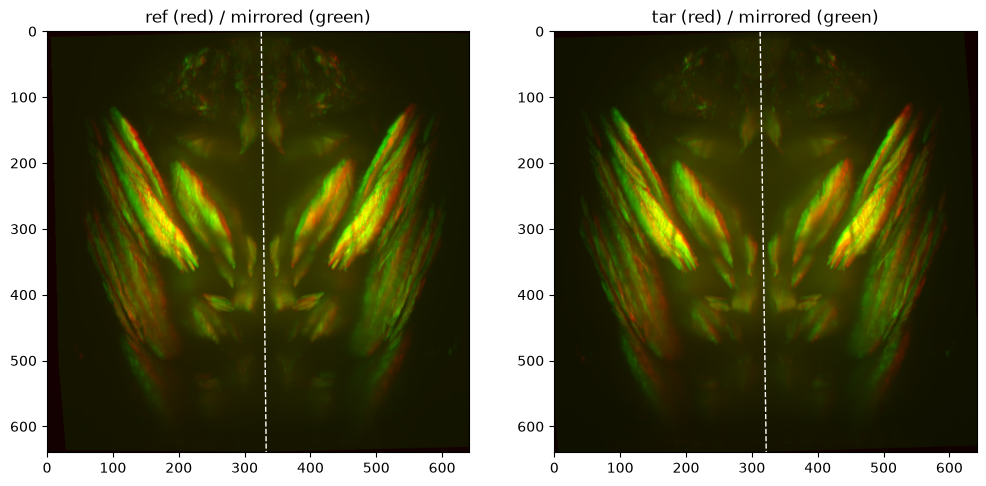

In [52]:
# CHECK SYMMETRY PLANE IS CORRECT
# mirror image and superimpose in red/green, for the reference and the target
# (isotropic voxels, so no aspect correction needed; projection along axis 0)

fig, axes = plt.subplots(1, 2, figsize=[12, 6])
for ax, key, plane in zip(axes, ['ref', 'tar'], [plane_ref, plane_tar]):
    mirrored = mirror_volume(iso[key], *plane)
    overlay = red_green_overlay(np.max(iso[key], axis=0), np.max(mirrored, axis=0), vmin=4.5)
    ax.imshow(overlay)
    ax.plot(*plane_line_in_projection(iso[key].shape, *plane), color='w', ls='--', lw=1)
    ax.set_title(f'{key} (red) / mirrored (green)')
plt.show()

### Replace blank background (padding/deskewing) to match rest of background

In [53]:
def replace_blank_background(image: np.ndarray, noise_mean: float = 110.0, narrow_factor: float = 10.0) -> np.ndarray:
    """
    Replaces blank-valued voxels in `image` - SCAPE deskewing margins
    and/or `pad_or_crop_to_shape` padding - with Poisson noise centered
    on the image's own noise floor, so a hard zero/background edge
    doesn't throw off registration.

    GCaMP fluorescence data is photon-count-like, so its shot noise is
    naturally Poisson-distributed; sampling `Poisson(lambda=noise_mean)`
    reproduces both the true background level (the distribution's mean)
    and a physically realistic spread (`sqrt(lambda)`). That spread is
    often wider than desired, so instead we sample
    `Poisson(lambda=noise_mean * narrow_factor) / narrow_factor`: this keeps
    the same mean (`noise_mean`) but shrinks the standard deviation by
    `1 / sqrt(narrow_factor)`, while staying Poisson-flavored rather
    than switching to an arbitrary distribution shape.

    Parameters
    ----------
    image : ndarray
        Image whose zero voxels should be filled. Not meant for
        label/mask volumes.
    noise_mean : float
        mean value for replaced noise
    narrow_factor : float
        How much to shrink the noise's standard deviation relative to
        plain `Poisson(lambda=noise_mean)` (`1` for no narrowing, higher
        for a tighter distribution around `noise_mean`).

    Returns
    -------
    ndarray
        `image`, with blank voxels replaced by Poisson noise.
    """
    zero_mask = image == 0
    noise = (np.random.poisson(lam=noise_mean * narrow_factor, size=int(zero_mask.sum()))
              / narrow_factor).astype(image.dtype)
    filled = image.copy()
    filled[zero_mask] = noise
    return filled

In [81]:
# fill background zeros with matching noise for every image, but leave the masks untouched
# hemi_filled = {key: (img if key.startswith('masks') else replace_blank_background(img))
#                         for key, img in hemi.items()}

hemi_filled = hemi

### Rigid pre-alignment between ref and target to initialize spam
Deform REFERENCE to match each target image (that's the goal). Deform also the reference labels.
Output is a matching deformed reference and labels per non-reference

In [82]:
# function to pad/crop to match shape - needed for pre-alignment

def pad_or_crop_to_shape(volume: np.ndarray, target_shape: tuple, pad_value: float = 0) -> np.ndarray:
    """
    Crops and/or zero-pads `volume` (centered, per axis) so its shape
    matches `target_shape` exactly.

    Crops first (if `volume` is larger than `target_shape` along an
    axis) and pads second (if it's smaller), both centered, so the
    volume's content stays centered in the output regardless of which
    axes needed cropping vs padding.

    Parameters
    ----------
    volume : ndarray
        Volume to crop/pad.

    target_shape : tuple of int
        Desired shape, same number of dimensions as `volume`.

    pad_value : float
        Fill value used for padded voxels (`0` by default, matching the
        background of `get_projection_images`'s deskewed volumes).

    Returns
    -------
    ndarray
        `volume`, cropped and/or padded to `target_shape`.
    """
    crop_slices = []
    for size, target in zip(volume.shape, target_shape):
        if size > target:
            start = (size - target) // 2
            crop_slices.append(slice(start, start + target))
        else:
            crop_slices.append(slice(None))
    cropped = volume[tuple(crop_slices)]

    pad_widths = []
    for size, target in zip(cropped.shape, target_shape):
        total_pad = max(target - size, 0)
        before = total_pad // 2
        after = total_pad - before
        pad_widths.append((before, after))
    return np.pad(cropped, pad_widths, mode='constant', constant_values=pad_value)

In [83]:
from skimage.registration import phase_cross_correlation
from scipy.ndimage import shift as ndi_shift

ref_id = 'ref_L'
lab_id = 'masks_' + ref_id[-1]
muscle_id = 'muscles_' + ref_id[-1]
tar_prealigned = {}
ref_prealigned = {}
lab_prealigned = {}
muscle_prealigned = {}

for id in hemi.keys():
    if id == ref_id or 'masks' in id:
        continue
    
    # pad/crop images to match shape
    final_shape = np.max([hemi[id].shape, hemi[ref_id].shape], 0)
    tar_padded = pad_or_crop_to_shape(hemi[id], final_shape)
    ref_padded = pad_or_crop_to_shape(hemi[ref_id], final_shape)
    lab_padded = pad_or_crop_to_shape(hemi[lab_id], final_shape)
    muscle_padded = pad_or_crop_to_shape(hemi[muscle_id], final_shape)

    # calculate rigid pre-alignment (of reference to target)
    global_shift, error, _ = phase_cross_correlation(
        tar_padded.astype(np.float64), ref_padded.astype(np.float64),
        upsample_factor=10, normalization=None,
    )
    print(id)
    print(f'Estimated global shift (voxels): {global_shift}, correlation error: {error:.4f}')

    # deform reference and reference masks to match target (muscles too)
    ref_prealigned[id] = ndi_shift(ref_padded, shift=global_shift, order=1, mode='constant', cval=0)
    lab_prealigned[id] = ndi_shift(lab_padded, shift=global_shift, order=0, mode='constant', cval=0)
    muscle_prealigned[id] = ndi_shift(muscle_padded, shift=global_shift, order=0, mode='constant', cval=0)
    # padded target
    tar_prealigned[id] = tar_padded
    if 'ref' in id:
        tar_prealigned['masks_'+id[-1]] = pad_or_crop_to_shape(hemi['masks_'+id[-1]], final_shape)
        print('(padded masks too)')


ref_R
Estimated global shift (voxels): [ 2.7  1.4 -8.4], correlation error: 0.2908
(padded masks too)
muscles_L
Estimated global shift (voxels): [-0.2 -0.4 -0.5], correlation error: 0.9584
tar_L
Estimated global shift (voxels): [-0.4 -1.2 -5.9], correlation error: 0.1933
tar_R
Estimated global shift (voxels): [ 1.4  0.9 -2.4], correlation error: 0.2955


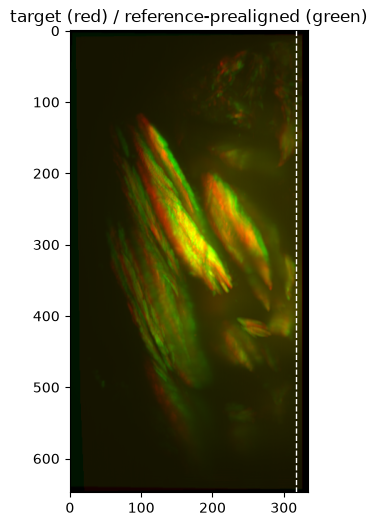

In [57]:
# CHECK rigid pre-alignment
id = 'ref_R'
overlay = red_green_overlay(np.max(tar_prealigned[id], axis=PROJ_AX), np.max(ref_prealigned[id], axis=PROJ_AX), vmin=4.5)

plt.figure(figsize=[6, 6])
plt.imshow(overlay)
plt.axvline(offset_axis2_tar, color='w', ls='--', lw=1)  # axis 2 maps to the image's x-axis here
plt.title('target (red) / reference-prealigned (green)')
plt.show()

### Normalize values?

In [58]:
# TODO

### Replace blank background AGAIN (padding) to match rest of background

In [59]:
# # fill background zeros with matching noise for every image, but leave the masks untouched
# ref_prealigned_fill = {key: (img if key.startswith('masks') else replace_blank_background(img))
#                         for key, img in ref_prealigned.items()}
# tar_prealigned_fill = {key: (img if key.startswith('masks') else replace_blank_background(img))
#                         for key, img in tar_prealigned.items()}

### Save images as tif to run spam

In [86]:
save_folder = main_path / 'spam' / 'tif_files'
save_folder.mkdir(parents=True, exist_ok=True)

for id in ref_prealigned.keys():
    if 'masks' in id or 'muscles' in id:
        continue

    ref_save_name = f'{id}_REFERENCE_prealigned.tif'
    tifffile.imwrite(save_folder / ref_save_name, ref_prealigned[id])

    tar_save_name = f'{id}_TARGET_prealigned.tif'
    tifffile.imwrite(save_folder / tar_save_name, tar_prealigned[id])

    lab_save_name = f'{id}_LABELS_prealigned.tif'
    tifffile.imwrite(save_folder / lab_save_name, lab_prealigned[id])

    muscle_save_name = f'{id}_MUSCLES_prealigned.tif'
    tifffile.imwrite(save_folder / muscle_save_name, muscle_prealigned[id])

    if 'ref' in id:
        tar_lab_save_name = f'{id}_TARGET_LABELS.tif'
        tifffile.imwrite(save_folder / tar_lab_save_name, tar_prealigned['masks_'+id[-1]])